In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from utils.dataset_lexicon_processing import sanitize_none_string

extracted_examples_df_path = "data/extracted_examples/extracted_examples_lemma_with_pos_mapped.csv"
extracted_examples = pd.read_csv(extracted_examples_df_path)
extracted_examples['sociodemographics_mapped'] = extracted_examples['sociodemographics_mapped'].apply(lambda x: sanitize_none_string(x))

[nltk_data] Downloading package punkt to /home/samuele/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/samuele/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /home/samuele/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/samuele/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
/tmp/ipykernel_160550/3541875816.py:6: DtypeWarning: Columns (0: original_label) have mixed types. Specify dtype option on import or set low_memory=False.
  extracted_examples = pd.read_csv(extracted_examples_df_path)


In [2]:
import os
figure_dir = "figures/demographic_pairwise_comparison"
os.makedirs(figure_dir, exist_ok=True)

In [3]:
import numpy as np
import ast
class DatasetProcessor():
    def __init__(self, extracted_examples_df_path, valid_sociodemographic_variables):
        self.extracted_examples_df_path = extracted_examples_df_path
        self.valid_sociodemographic_variables = valid_sociodemographic_variables
        
        self.extracted_examples = pd.read_csv(extracted_examples_df_path, dtype={'original_label': str})

        # Ensure sociodemographics and tags are read as dictionary
        self._postprocess_extracted_examples()
    
    def _postprocess_extracted_examples(self):
        self.extracted_examples['sociodemographics_mapped'] = self.extracted_examples['sociodemographics_mapped'].apply(lambda x: sanitize_none_string(x))
        self.extracted_examples['tag'] = self.extracted_examples['tag'].apply(lambda x: ast.literal_eval(x) if not pd.isna(x) else None)

    # Method to obtain gold label for each text given the specified sociodemographics (either single or multiple) -> Useful both for plotting and for the LMM part later
    def get_gold_label_dataset_based_on_sociodemographics(self, sociodemographics, tie_break_strategy='exclude'):
        """
        sociodemographics: list of sociodemographic attributes to consider
        tie_break_strategy: 'first', 'random', or 'exclude'
        """
        assert all(s in self.valid_sociodemographic_variables for s in sociodemographics)

        def filter_by_sociodemographics(row):
            if row['sociodemographics_mapped'] is None:
                return False
            for soc in sociodemographics:
                if soc not in row['sociodemographics_mapped']:
                    return False
                if row['sociodemographics_mapped'][soc] is None:
                    return False
            return True
        
        filtered_df = self.extracted_examples[self.extracted_examples.apply(filter_by_sociodemographics, axis=1)].copy()

        # Prep for grouping
        filtered_df['sociodemographics_mapped_subset'] = filtered_df['sociodemographics_mapped'].apply(lambda x: str(dict(sorted({soc: x[soc] for soc in sociodemographics}.items()))))
        filtered_df['tag'] = filtered_df['tag'].apply(lambda x: str(sorted(x)) if x is not None else None)

        def resolve_mode(x):
            modes = x.mode()
            if len(modes) == 0:
                return None
            if len(modes) > 1:
                if tie_break_strategy == 'random':
                    return modes.sample(1).values[0]
                elif tie_break_strategy == 'exclude':
                    return np.nan  # We will drop these rows after aggregation
                # Default 'first' behavior
                return modes[0]
            return modes[0]

        # Aggregate using the custom resolver
        output_df = filtered_df.groupby(['text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped_subset'])['label'].agg(resolve_mode).reset_index()

        # If strategy was 'exclude', remove the tied rows
        if tie_break_strategy == 'exclude':
            initial_count = len(output_df)
            output_df = output_df.dropna(subset=['label'])
            print(f"Excluded {initial_count - len(output_df)} tied instances ({(initial_count - len(output_df)) / initial_count * 100:.2f}%).")

        # Cleanup and back-conversion
        output_df['sociodemographics_mapped_subset'] = output_df['sociodemographics_mapped_subset'].apply(lambda x: eval(x))
        output_df['tag'] = output_df['tag'].apply(lambda x: set(ast.literal_eval(x)) if not pd.isna(x) else None)
        output_df.rename(columns={'sociodemographics_mapped_subset': 'sociodemographics_mapped'}, inplace=True)
        
        return output_df

In [4]:
valid_sociodemographic_variables = {'age', 
                                    'gender', 
                                    'education', 
                                    'ideology', 
                                    'race'}
dprocessor = DatasetProcessor(extracted_examples_df_path, valid_sociodemographic_variables)

In [5]:
age_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['age'])
race_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['race'])
gender_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['gender'])
education_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['education'])
ideology_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['ideology'])

Excluded 4034 tied instances (6.63%).
Excluded 2758 tied instances (6.44%).
Excluded 3638 tied instances (8.08%).
Excluded 804 tied instances (8.07%).
Excluded 2992 tied instances (6.36%).


In [6]:
# 'text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped_subset'
# Find instances with duplicates on those columns in the original extracted_examples dataframe
# 'text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped'
# Find instances with duplicates on those columns in the original extracted_examples dataframe

def make_hashable(x):
    if isinstance(x, dict):
        return tuple(sorted((k, make_hashable(v)) for k, v in x.items()))
    if isinstance(x, set):
        return tuple(sorted(make_hashable(v) for v in x))
    if isinstance(x, list):
        return tuple(make_hashable(v) for v in x)
    return x

tmp = age_aggregated_df.assign(
    tag_hash=age_aggregated_df["tag"].apply(make_hashable),
    sociodemographics_mapped_hash=age_aggregated_df["sociodemographics_mapped"].apply(make_hashable),
)

duplicate_instances = age_aggregated_df[
    tmp.duplicated(
        subset=["text_id", "lemma_with_pos", "tag_hash", "sociodemographics_mapped_hash"],
        keep=False
    )
]

print(f"Number of duplicate instances in the original extracted_examples dataframe: {len(duplicate_instances)}")

Number of duplicate instances in the original extracted_examples dataframe: 0


In [7]:
def preprocess_for_category_pairwise_analysis(aggregated_df):
    """
    Duplicates at tag level appear if a text matches with multiple lemmas with same tag
    """
    aggregated_df = aggregated_df[['text_id', 'tag', 'sociodemographics_mapped', 'label']].explode('tag').reset_index(drop=True)
    # Remove duplicates 
    aggregated_df = aggregated_df.assign(
        sociodemographics_mapped_str=aggregated_df['sociodemographics_mapped'].astype(str)
    )
    
    aggregated_df = aggregated_df.drop_duplicates(
        subset=['text_id', 'tag', 'sociodemographics_mapped_str', 'label']
    ).drop(columns=['sociodemographics_mapped_str']).reset_index(drop=True)
    
    return aggregated_df

In [8]:
"""def preprocess_for_lemma_pairwise_analysis(aggregated_df):
    aggregated_df = aggregated_df[['text_id', 'lemma_with_pos', 'sociodemographics_mapped', 'label']].reset_index(drop=True)

    # Remove duplicates 
    aggregated_df = aggregated_df.assign(
        sociodemographics_mapped_str=aggregated_df['sociodemographics_mapped'].astype(str)
    )
    print(f"len aggregated_df before dropping duplicates: {len(aggregated_df)}")
    aggregated_df = aggregated_df.drop_duplicates(
        subset=['text_id', 'lemma_with_pos', 'sociodemographics_mapped_str', 'label']
    ).drop(columns=['sociodemographics_mapped_str']).reset_index(drop=True)
    print(f"len aggregated_df after dropping duplicates: {len(aggregated_df)}")
    # print(f"Dropped {len(aggregated_df) - len(aggregated_df.drop_duplicates(subset=['text_id', 'lemma_with_pos', 'sociodemographics_mapped', 'label']))} duplicate instances for lemma pairwise analysis.")

    return aggregated_df
""";

In [8]:
age_aggregated_df_category = preprocess_for_category_pairwise_analysis(age_aggregated_df)
race_aggregated_df_category = preprocess_for_category_pairwise_analysis(race_aggregated_df)
gender_aggregated_df_category = preprocess_for_category_pairwise_analysis(gender_aggregated_df)
education_aggregated_df_category = preprocess_for_category_pairwise_analysis(education_aggregated_df)
ideology_aggregated_df_category = preprocess_for_category_pairwise_analysis(ideology_aggregated_df)

In [10]:
"""age_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(age_aggregated_df)
race_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(race_aggregated_df)
gender_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(gender_aggregated_df)
education_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(education_aggregated_df)
ideology_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(ideology_aggregated_df)
""";

In [9]:
from itertools import combinations
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def calculate_pairwise_weights(df, 
                               variable_name, 
                               use_lemmas=False):
    df = df.copy()
    df[variable_name] = df['sociodemographics_mapped'].apply(lambda x: x.get(variable_name))
    df = df.dropna(subset=[variable_name])

    # --- Choose the feature column ---
    feature_col = 'lemma_with_pos' if use_lemmas else 'tag'

    unique_groups = df[variable_name].unique()
    all_results = {}

    for val1, val2 in combinations(unique_groups, 2):
        comparison_key = f"{val1} vs {val2}"

        group_counts = df.groupby('text_id')[variable_name].apply(set)
        valid_ids = group_counts[group_counts.apply(lambda x: {val1, val2}.issubset(x))].index

        if len(valid_ids) == 0:
            continue

        pair_df = df[(df['text_id'].isin(valid_ids)) & (df[variable_name].isin({val1, val2}))]

        # For tags, explode (list column); for lemmas, rows are already one-per-lemma
        if use_lemmas:
            exploded_df = pair_df.copy()
        else:
            exploded_df = pair_df.explode(feature_col)

        tag_data = {}
        unique_features = exploded_df[feature_col].dropna().unique()

        for feature in unique_features:
            tag_df = exploded_df[exploded_df[feature_col] == feature]

            tag_group_counts = tag_df.groupby('text_id')[variable_name].apply(set)
            tag_valid_ids = tag_group_counts[
                tag_group_counts.apply(lambda x: {val1, val2}.issubset(x))
            ].index

            tag_specific_df = tag_df[tag_df['text_id'].isin(tag_valid_ids)]
            n_texts_for_tag = len(tag_valid_ids)

            if n_texts_for_tag > 0:
                comparison_pivot = tag_specific_df.pivot(
                    index='text_id', columns=variable_name, values='label'
                )
                a_more_sensitive = (
                    (comparison_pivot[val1] == 'hurtful') &
                    (comparison_pivot[val2] == 'not_hurtful')
                ).sum()
                b_more_sensitive = (
                    (comparison_pivot[val2] == 'hurtful') &
                    (comparison_pivot[val1] == 'not_hurtful')
                ).sum()

                w_a = (a_more_sensitive - b_more_sensitive) / n_texts_for_tag
                tag_data[feature] = {
                    "weight": round(w_a, 2),
                    "n_texts": n_texts_for_tag
                }

        all_results[comparison_key] = tag_data

    return all_results

In [ ]:
"""import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_tag_weights(results_dict, min_samples=50, keep_lemmas=None, save_path=None):
    data_list = []
    for comparison, tags in results_dict.items():
        for tag, stats in tags.items():
            if stats['n_texts'] >= min_samples:
                data_list.append({
                    'Comparison': comparison,
                    'Category': tag,
                    'Weight': stats['weight'],
                    'N': stats['n_texts']
                })

    if not data_list:
        print(f"No categories met the minimum sample size of {min_samples}.")
        return

    plot_df = pd.DataFrame(data_list)

    # --- Filter to top-k lemmas by max abs weight across any comparison ---
    if keep_lemmas is not None:
        top_categories = (
            plot_df.groupby('Category')['Weight']
            .apply(lambda x: x.abs().max())
            .nlargest(keep_lemmas)
            .index
        )
        plot_df = plot_df[plot_df['Category'].isin(top_categories)]

    pivot_df = plot_df.pivot(index='Category', columns='Comparison', values='Weight')

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        pivot_df,
        annot=True,
        cmap='RdBu_r',
        center=0,
        cbar_kws={'label': 'Bias Weight (w_a)'}
    )
    plt.title(f'Tag Weights by Comparison (min_samples={min_samples})')
    plt.ylabel('Category (Tag)')
    plt.xlabel('Sociodemographic Pair')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    return plot_df"""

In [ ]:
"""import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_tag_weights(results_dict, variable_name, min_samples=50, keep_lemmas=None, 
                     divergence_threshold=0.20, save_path=None):
    # --- 1. Define strict hierarchies ---
    category_orders = {
        'race': ['white', 'asian', 'black', 'hispanic', 'native'],
        'gender': ['man', 'woman', 'non-binary'],
        'age': ['18-24', '25-34', '35-44', '45-54', '55-64', '65 or older'],
        'ideology': ['left', 'right'],
        'education': ['less_than_high_school', 'high_school_diploma', 'bachelors_degree', 'graduate_degree']
    }
    
    edu_map = {'less_than_high_school': '<Dipl', 'high_school_diploma': 'Dipl', 
               'bachelors_degree': 'BA', 'graduate_degree': 'Grad'}

    order_list = category_orders.get(variable_name, [])
    data_list = []

    # --- 2. Build and Re-orient Data ---
    for comparison, tags in results_dict.items():
        g_a, g_b = comparison.split(" vs ")
        if 'other' in g_a.lower() or 'other' in g_b.lower(): continue

        try:
            idx_a, idx_b = order_list.index(g_a), order_list.index(g_b)
            first, second, mult = (g_a, g_b, 1) if idx_a < idx_b else (g_b, g_a, -1)
            sort_priority = tuple(sorted((idx_a, idx_b)))
        except ValueError:
            first, second, mult, sort_priority = g_a, g_b, 1, (99, 99)

        for tag, stats in tags.items():
            if stats['n_texts'] >= min_samples:
                data_list.append({
                    'Comparison': f"{edu_map.get(first, first)} vs {edu_map.get(second, second)}",
                    'Category': tag,
                    'Weight': stats['weight'] * mult,
                    'sort_key': sort_priority
                })

    if not data_list: return print(f"No data for {variable_name}")
    plot_df = pd.DataFrame(data_list)

    # --- 3. Filter Categories and Divergence ---
    if keep_lemmas:
        top_cats = plot_df.groupby('Category')['Weight'].apply(lambda x: x.abs().max()).nlargest(keep_lemmas).index
        plot_df = plot_df[plot_df['Category'].isin(top_cats)]

    if variable_name.lower() != 'gender':
        valid_comps = plot_df.groupby('Comparison')['Weight'].apply(lambda x: x.abs().max() >= divergence_threshold)
        plot_df = plot_df[plot_df['Comparison'].isin(valid_comps[valid_comps].index)]

    if plot_df.empty: return print(f"No comparisons met threshold for {variable_name}")

    # --- 4. Pivot and Sort ---
    comp_order = plot_df[['Comparison', 'sort_key']].drop_duplicates().sort_values('sort_key')['Comparison'].tolist()
    pivot_df = plot_df.pivot(index='Category', columns='Comparison', values='Weight').reindex(columns=comp_order)

    # --- 5. High-Resolution Plotting ---
    fig_width = max(10, len(comp_order) * 2.2)
    fig_height = max(8, len(pivot_df) * 0.75)
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    # Scale fixed to [-1, 1]
    sns.heatmap(pivot_df, 
                annot=True, 
                fmt=".2f",
                cmap='PiYG', 
                center=0, 
                vmin=-0.6, 
                vmax=0.6, 
                annot_kws={"size": 18, "weight": "bold"},
                cbar_kws={
                    'label': r'$w_{AB}$', 
                    'location': 'top', 
                    'shrink': 0.4, 
                    'pad': 0.03
                },
                ax=ax)

    # Formatting Legend and Ticks
    cbar = ax.collections[0].colorbar
    cbar.set_label(r'$w_{AB}$', size=24, weight='bold', labelpad=10)
    cbar.ax.tick_params(labelsize=16)

    ax.set_xlabel('Demographic Comparison', fontsize=20, fontweight='semibold', labelpad=12)
    ax.set_ylabel('Lemma / Category', fontsize=20, fontweight='semibold', labelpad=12)
    
    plt.xticks(rotation=35, ha='right', fontsize=18)
    plt.yticks(fontsize=18)
    
    plt.tight_layout(pad=0.2)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()""";

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_tag_weights(results_dict, variable_name, min_samples=50, keep_lemmas=None, 
                     col_divergence_threshold=0.20, 
                     row_divergence_threshold=0.20,
                     save_path=None):
    # --- 1. Define strict hierarchies ---
    category_orders = {
        'race': ['white', 'asian', 'black', 'hispanic', 'native'],
        'gender': ['man', 'woman', 'non-binary'],
        'age': ['18-24', '25-34', '35-44', '45-54', '55-64', '65 or older'],
        'ideology': ['left', 'right'],
        'education': ['less_than_high_school', 'high_school_diploma', 'bachelors_degree', 'graduate_degree']
    }
    edu_map = {'less_than_high_school': '<Dipl', 'high_school_diploma': 'Dipl', 
               'bachelors_degree': 'BA', 'graduate_degree': 'Grad'}
    

    order_list = category_orders.get(variable_name, [])
    data_list = []

    # --- 2. Build and Re-orient Data ---
    for comparison, tags in results_dict.items():
        g_a, g_b = comparison.split(" vs ")
        if 'other' in g_a.lower() or 'other' in g_b.lower(): continue

        try:
            idx_a, idx_b = order_list.index(g_a), order_list.index(g_b)
            first, second, mult = (g_a, g_b, 1) if idx_a < idx_b else (g_b, g_a, -1)
            sort_priority = tuple(sorted((idx_a, idx_b)))
        except ValueError:
            first, second, mult, sort_priority = g_a, g_b, 1, (99, 99)

        for tag, stats in tags.items():
            if stats['n_texts'] >= min_samples:
                label_a = edu_map.get(first, first)
                label_b = edu_map.get(second, second)
                data_list.append({
                    'Comparison': f"{label_a}\nvs\n{label_b}",
                    'Category': tag,
                    'Weight': stats['weight'] * mult,
                    'sort_key': sort_priority
                })

    if not data_list: return
    plot_df = pd.DataFrame(data_list)

    # --- 3. Filter Columns (Pruning non-divergent demographics) ---
    if variable_name.lower() not in ['gender', 'ideology']:
        valid_comps = (plot_df.groupby('Comparison')['Weight']
                       .apply(lambda x: x.abs().max() >= col_divergence_threshold))
        plot_df = plot_df[plot_df['Comparison'].isin(valid_comps[valid_comps].index)]

    if plot_df.empty: return

    # --- 4. Sort and Filter Rows (Categories/Lemmas) ---
    row_magnitudes = (plot_df.groupby('Category')['Weight']
                      .apply(lambda x: x.abs().max())
                      .sort_values(ascending=False))
    
    # Logic: Keep rows >= row_divergence_threshold OR the top 5
    significant_rows = row_magnitudes[row_magnitudes >= row_divergence_threshold].index.tolist()
    #top_5_rows = row_magnitudes.head(5).index.tolist()
    
    final_row_order = [r for r in row_magnitudes.index if r in set(significant_rows )] # + top_5_rows
    
    if keep_lemmas:
        final_row_order = final_row_order[:keep_lemmas]
    
    plot_df = plot_df[plot_df['Category'].isin(final_row_order)]

    # --- 5. Pivot and Sort ---
    comp_order = plot_df[['Comparison', 'sort_key']].drop_duplicates().sort_values('sort_key')['Comparison'].tolist()
    pivot_df = plot_df.pivot(index='Category', columns='Comparison', values='Weight')
    pivot_df = pivot_df.reindex(index=final_row_order, columns=comp_order)

    # --- 6. Compact Plotting for One-Column Layout ---
    n_cols = len(comp_order)
    n_rows = len(pivot_df)
    
    fig_width = max(5, n_cols * 1.3) 
    if variable_name == 'gender':
        fig_height = 2.3
    else:
        fig_height = max(6, n_rows * 0.65)
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    # Scale fixed to [-0.6, 0.6] with ticks every 0.2
    cbar_ticks = [-0.6, -0.3, 0.0, 0.3, 0.6]
    
    sns.heatmap(pivot_df, 
                annot=True, 
                fmt=".2f",
                cmap='PiYG', 
                center=0, 
                vmin=-0.6, vmax=0.6, 
                annot_kws={"size": 14, "weight": "bold"}, 
                cbar_kws={
                    'label': r'$w_{AB}$', 
                    'location': 'top', 
                    'shrink': 0.5, 
                    'pad': 0.04,
                    'ticks': cbar_ticks
                },
                linewidths=0.7, 
                ax=ax)

    # Legend & Label adjustments
    cbar = ax.collections[0].colorbar
    cbar.set_label(r'$w_{AB}$', size=20, weight='bold', labelpad=10)
    cbar.ax.tick_params(labelsize=14)

    ax.set_xlabel('', fontsize=0)
    ax.set_ylabel('Lemma / Category', fontsize=16, fontweight='semibold')
    
    plt.xticks(rotation=0, fontsize=16, fontweight='medium') 
    plt.yticks(fontsize=16)
    
    plt.tight_layout(pad=0.1)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

In [14]:
all_variables_plots = {
    'gender': gender_aggregated_df_category,
    'age': age_aggregated_df_category,
    'race': race_aggregated_df_category,
    'ideology': ideology_aggregated_df_category,
    'education': education_aggregated_df_category,
}

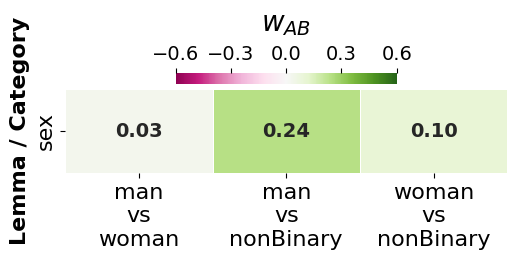

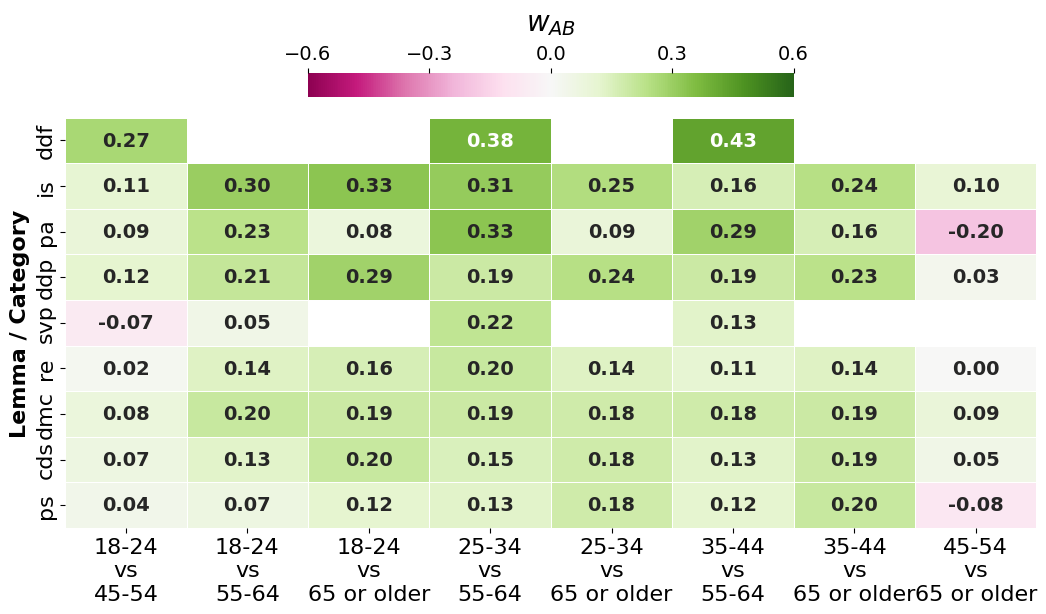

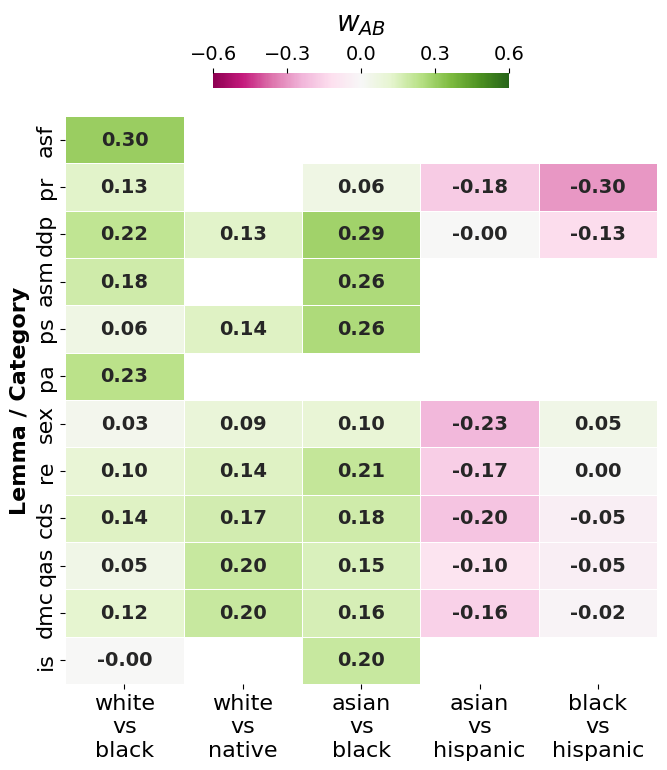

/home/samuele/miniconda3/envs/hurtpersp_env/lib/python3.12/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/home/samuele/miniconda3/envs/hurtpersp_env/lib/python3.12/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))


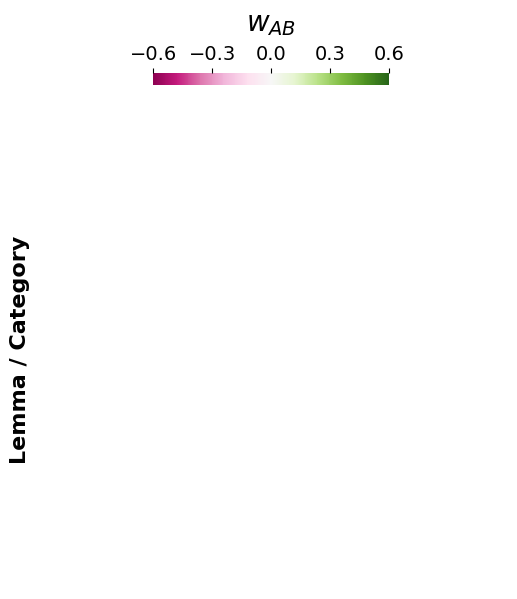

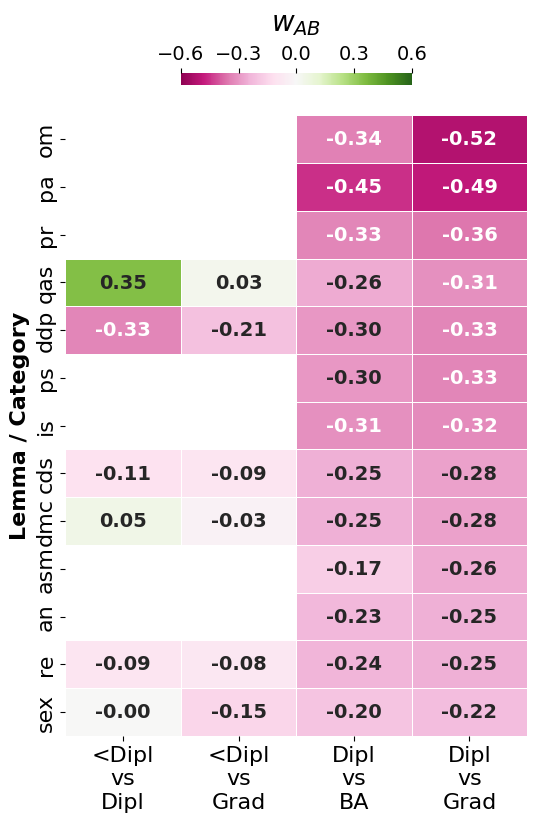

In [18]:
figure_dir = f"figures/demographic_pairwise_comparison/category_based_exclude_ties"
os.makedirs(figure_dir, exist_ok=True)
for var, df in all_variables_plots.items():
    results = calculate_pairwise_weights(df, var)
    figure_path = f"{figure_dir}/{var}_demographic_pairwise_plot.pdf"
    plot_tag_weights(results, variable_name=var,min_samples=20, save_path=figure_path)

- - - 
### Visualizations for Lemmas

In [11]:
all_variables_plots = {
    'gender': gender_aggregated_df,
    'age': age_aggregated_df,
    'race': race_aggregated_df,
    'ideology': ideology_aggregated_df,
    'education': education_aggregated_df,
}

/home/samuele/miniconda3/envs/hurtpersp_env/lib/python3.12/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/home/samuele/miniconda3/envs/hurtpersp_env/lib/python3.12/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))


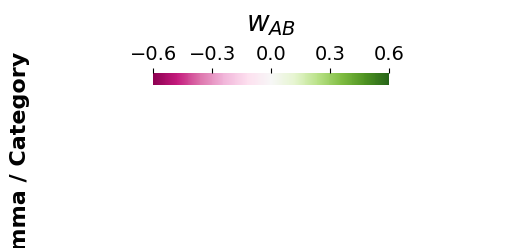

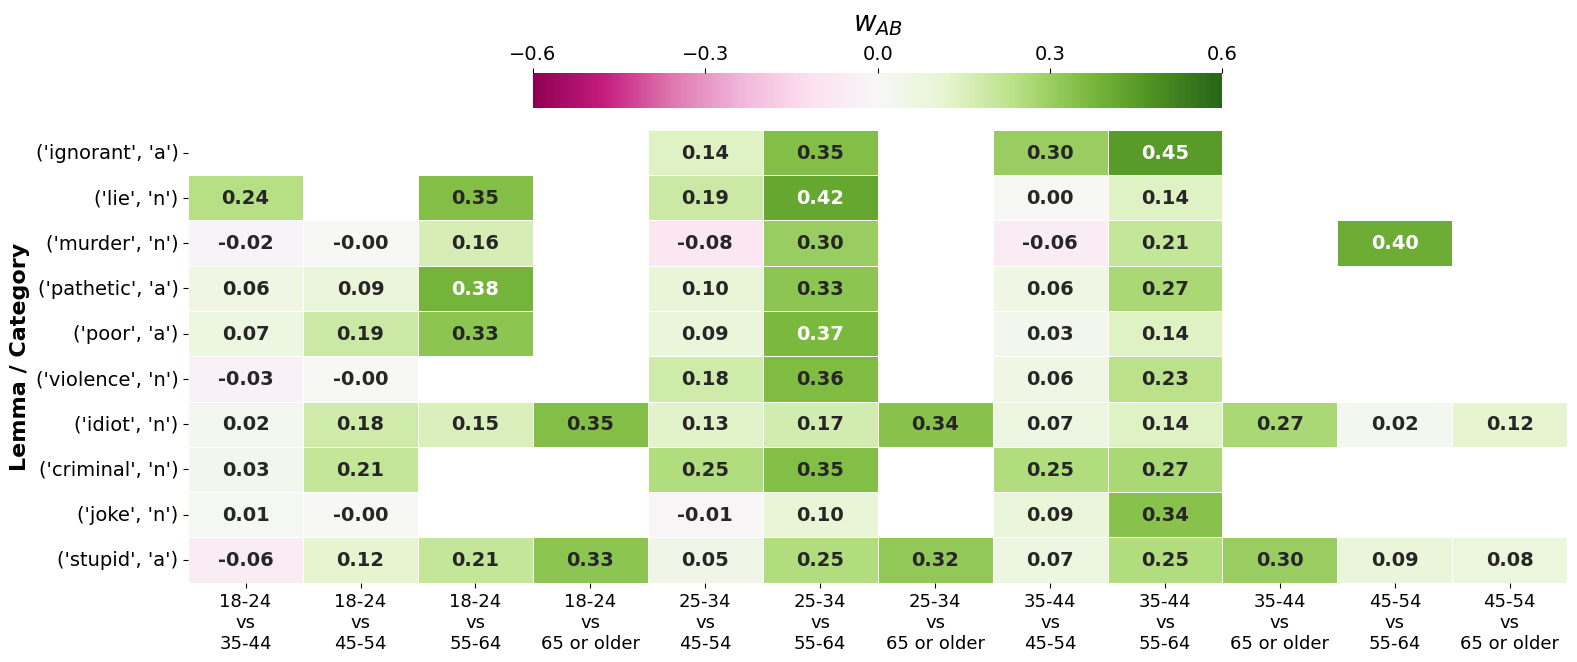

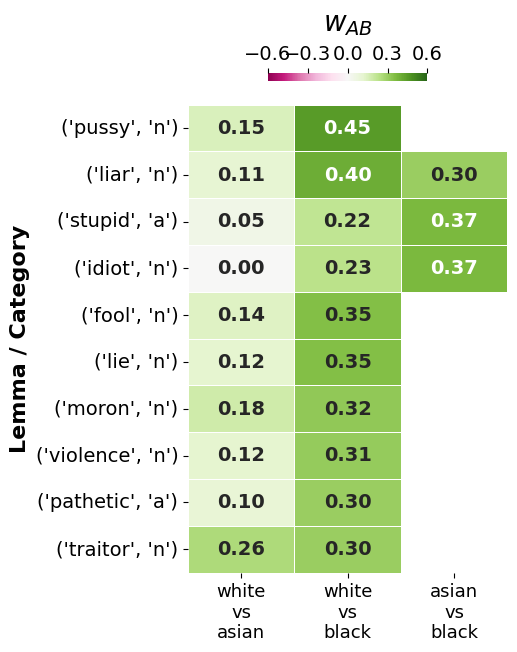

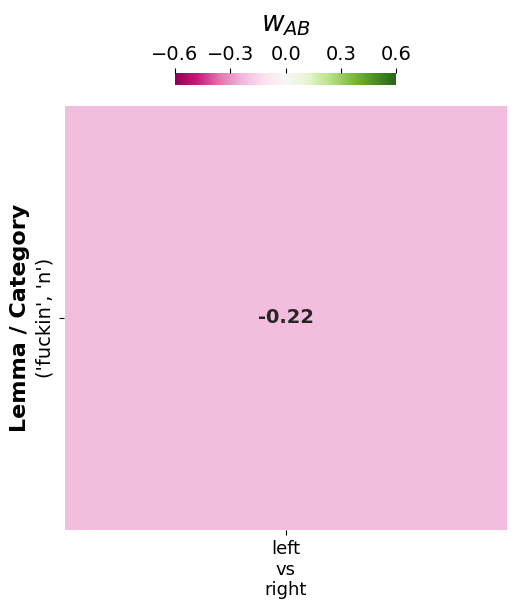

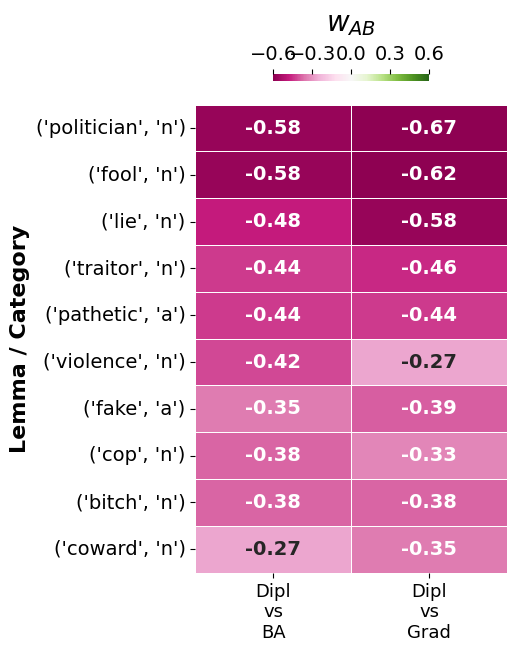

In [13]:
figure_dir = f"figures/demographic_pairwise_comparison/lemma_based_exclude_ties"
os.makedirs(figure_dir, exist_ok=True)
for var, df in all_variables_plots.items():
    results = calculate_pairwise_weights(df, use_lemmas=True, variable_name=var)
    figure_path = f"{figure_dir}/{var}_demographic_pairwise_plot.pdf"
    plot_tag_weights(results, min_samples=20, variable_name=var, save_path=figure_path, keep_lemmas=10)